In [1]:
from pca_utils import *

# Import data

In [10]:
path1 = "/mnt/c/users/helen/Desktop/190226_Outsu_PCA/WT/foci2/aggregated_data.csv"
path2 = "/mnt/c/users/helen/Desktop/190226_Outsu_PCA/As_100uM_2h/foci2/aggregated_data.csv"
path3 = "/mnt/c/users/helen/Desktop/190226_Outsu_PCA/As_100uM_4h/foci2/aggregated_data.csv"

df1 = pd.read_csv(path1)
df2 = pd.read_csv(path2)
df3 = pd.read_csv(path3)

df1["sample"] = "Control"
df2["sample"] = "Sodium Arsenite, 2 h"
df3["sample"] = "Sodium Arsenite, 4 h"

combined_df = pd.concat(
    [df1, df2, df3],
    ignore_index=True
)

In [ ]:
path1 = "/mnt/c/users/helen/Desktop/190226/WT/foci2/aggregated_data.csv"
path2 = "/mnt/c/users/helen/Desktop/190226/MGS1/foci2/aggregated_data.csv"
path3 = "/mnt/c/users/helen/Desktop/190226/MGS2/foci2/aggregated_data.csv"
path4 = "/mnt/c/users/helen/Desktop/190226/MGS3/foci2/aggregated_data.csv"
path5 = "/mnt/c/users/helen/Desktop/190226/MGS4/foci2/aggregated_data.csv"
path6 = "/mnt/c/users/helen/Desktop/190226/MGS5/foci2/aggregated_data.csv"

df1 = pd.read_csv(path1)
df2 = pd.read_csv(path2)
df3 = pd.read_csv(path3)
df4 = pd.read_csv(path4)
df5 = pd.read_csv(path5)
df6 = pd.read_csv(path6)

df1["sample"] = "WT"
df2["sample"] = "MGS1"
df3["sample"] = "MGS2"
df4["sample"] = "MGS3"
df5["sample"] = "MGS4"
df6["sample"] = "MGS5"

combined_df = pd.concat(
    [df1, df2, df3, df4, df5, df6],
    ignore_index=True
)

### Clean data

In [11]:
# Clean data
combined_df.columns = combined_df.columns.str.strip().str.lower()
combined_df.iloc[:, 1:10] = combined_df.iloc[:, 1:10].apply(pd.to_numeric, errors="coerce")
df = combined_df.dropna()

print("Number of cells is:", df.shape[0])

Number of cells is: 93


# Correlation analysis

In [12]:
# Select numerical columns
df_numeric = df.select_dtypes(include=np.number)

# Calculate Spearman correlation
corr = df_numeric.corr(method="spearman")

display(corr.round(3))

,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity
n_foci,1.000,-0.866,-0.866,0.850,0.774,-0.840,-0.731,-0.753,-0.704
area,-0.866,1.000,1.000,-0.904,-0.856,0.937,0.772,0.800,0.738
equivalent_diameter_area,-0.866,1.000,1.000,-0.903,-0.857,0.937,0.772,0.800,0.738
eccentricity,0.850,-0.904,-0.903,1.000,0.773,-0.962,-0.796,-0.816,-0.761
solidity,0.774,-0.856,-0.857,0.773,1.000,-0.817,-0.672,-0.703,-0.636
perimeter,-0.840,0.937,0.937,-0.962,-0.817,1.000,0.774,0.799,0.735
mean_intensity,-0.731,0.772,0.772,-0.796,-0.672,0.774,1.000,0.997,0.996
max_intensity,-0.753,0.800,0.800,-0.816,-0.703,0.799,0.997,1.000,0.990
min_intensity,-0.704,0.738,0.738,-0.761,-0.636,0.735,0.996,0.990,1.000


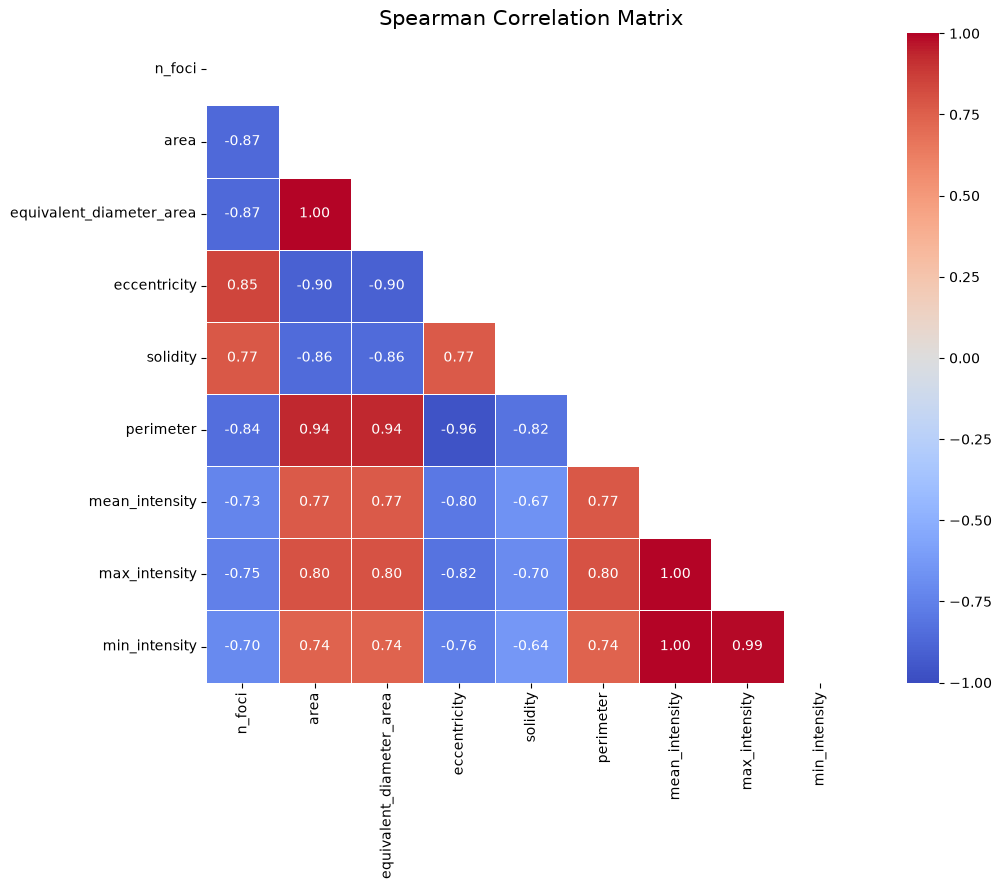

In [13]:
plt.figure(figsize=(12, 9))

# Show only lower triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Spearman Correlation Matrix", fontsize=15)
plt.tight_layout()
plt.show()

## Graphs

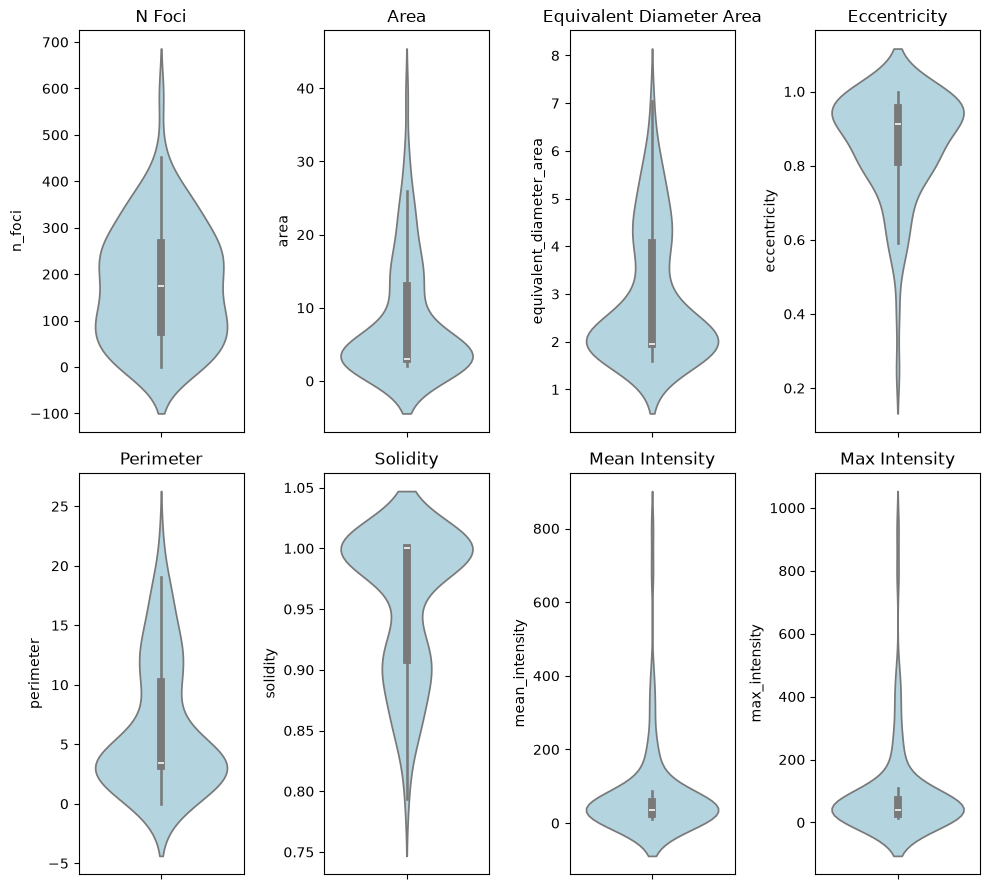

In [14]:
features = [
    "n_foci",
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
]

fig, axes = plt.subplots(2, 4, figsize=(10, 9))

for ax, feature in zip(axes.flat, features):

    sns.violinplot(
        data=df,
        y=feature,
        color="lightblue",
        inner="box",
        legend=False,
        ax=ax
    )
    
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


# PCA

In [34]:
# Features
features = [
    "n_foci",
    #"area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    #"max_intensity",
    #"min_intensity",
]

# Select features and scale them
pca_df = df.copy()

X = df[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

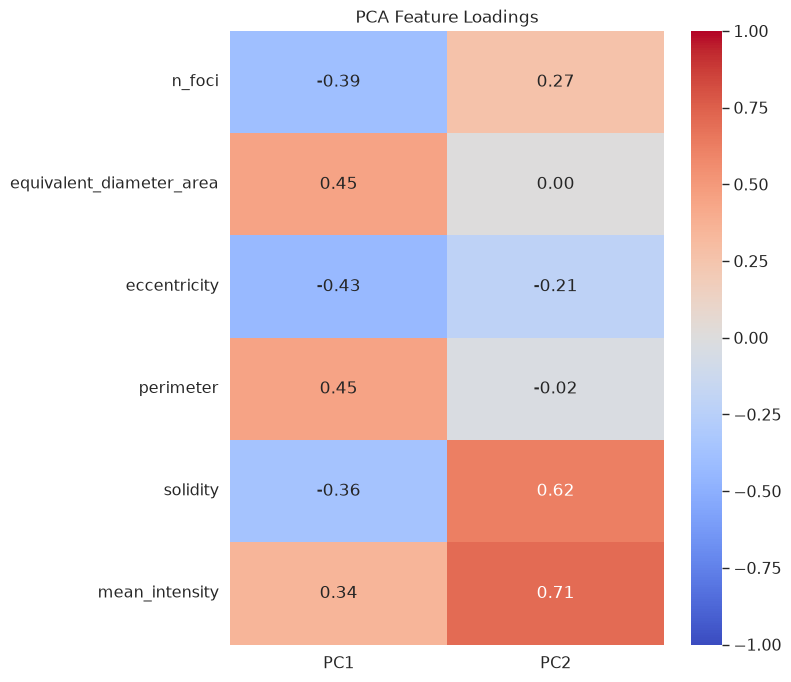

In [35]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

In [36]:
centroids = pca_df.groupby("sample")[["PC1", "PC2"]].mean()

print(centroids)

                           PC1       PC2
sample                                  
Control              -1.441748  0.121975
Sodium Arsenite, 2 h  0.809792  0.299065
Sodium Arsenite, 4 h  0.934551 -0.472895


In [ ]:
#centroids = plot_pca_centroids_ci(
    #pca_df,
    #group_col="sample",
    #confidence=0.95
#)

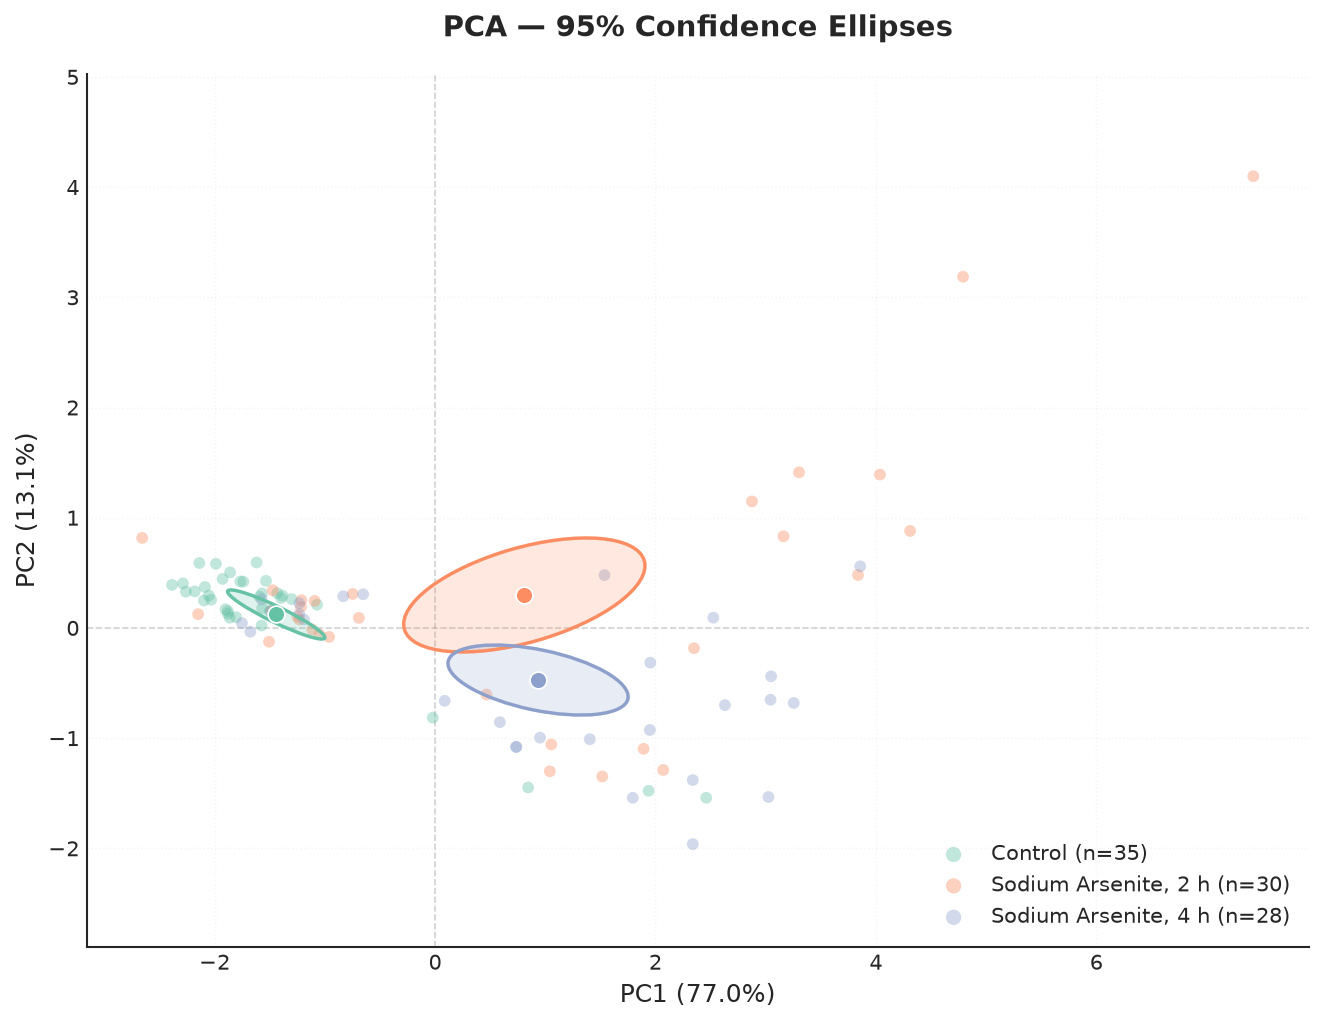

In [37]:
results = bootstrap_pca_centroids(
    pca_df,
    group_col="sample",
    pca=pca,
    confidence=0.95,
    palette="Set2",
    centroid_size=65,
    show_bootstrap=False
)

In [38]:
results_stats = pca_permanova(
    pca_df,
    group_col="sample"
)

results_stats

,Test,Statistic,p_value,R2,n,groups
0,PERMANOVA,15.105875,0.0001,0.251321,93,3
1,PERMDISP,10.191031,0.0006,NaN,93,3


In [41]:
subset = pca_df[(pca_df['sample'] == "Control") | (pca_df['sample'] == "Sodium Arsenite, 4 h")]

results_stats = pca_permanova(
    subset,
    group_col="sample"
)

results_stats

,Test,Statistic,p_value,R2,n,groups
0,PERMANOVA,37.699715,0.0001,0.381964,63,2
1,PERMDISP,17.301675,0.0025,NaN,63,2


### Centroids distances tree

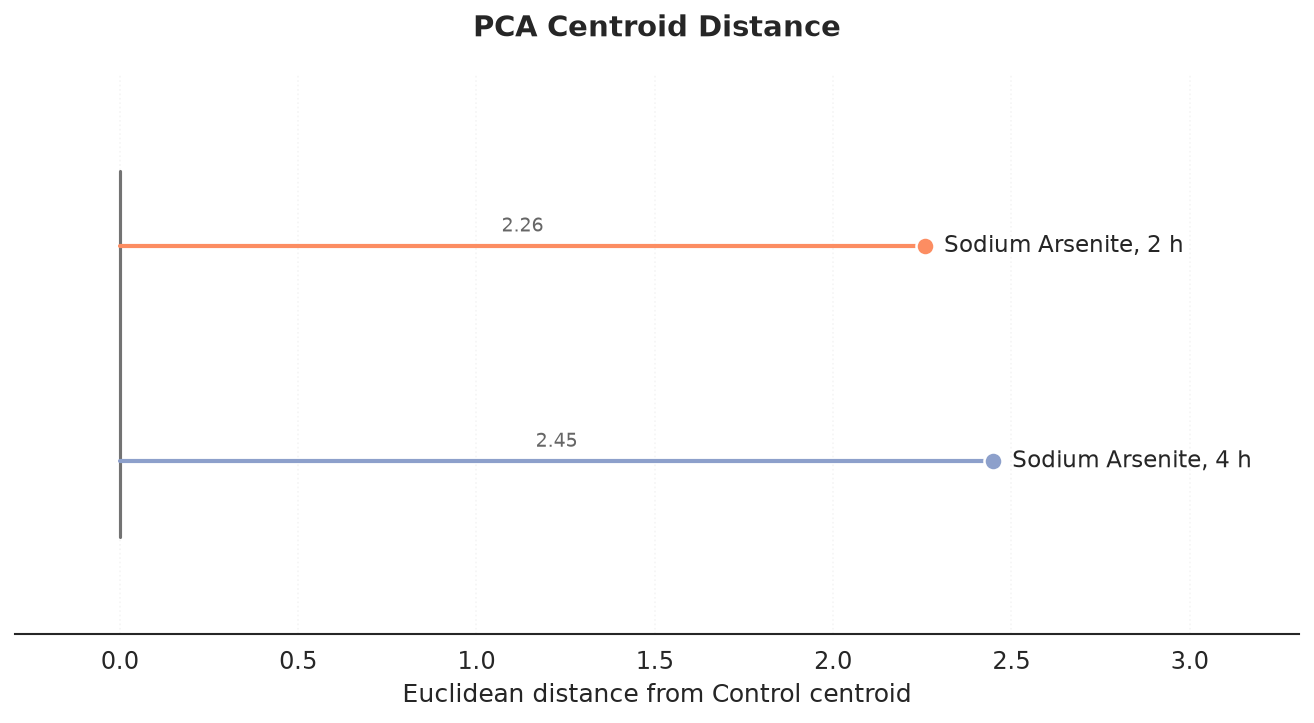

In [40]:
distances = plot_centroid_distance_tree(
    results,
    reference="Control",
    palette="Set2"
)

# Detect outliers

In [42]:
pca_df_outliers = detect_pca_outliers(
    pca_df,
    group_col="sample",
    features=("PC1", "PC2"),
    confidence=0.99
)

# Display detected outliers
outliers = pca_df_outliers[
    pca_df_outliers["outlier"]
]

display(outliers)

,image_id,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,sample,PC1,PC2,mahalanobis_distance,outlier
4,C2_MP_U2OS_fixed_WT_001.nd2_(series_11)_ROI_02...,49,6.0,2.763953,0.836390,0.868421,6.414214,30.000000,35.0,25.0,Control,0.844323,-1.447909,3.243973,True
16,C2_MP_U2OS_fixed_WT_001.nd2_(series_25)_ROI_02...,83,13.0,4.068429,0.816497,0.835616,11.035534,71.000000,84.0,61.0,Control,1.938034,-1.477874,3.083159,True
18,C2_MP_U2OS_fixed_WT_001.nd2_(series_27)_ROI_02...,84,16.0,4.513517,0.807260,0.820561,13.553301,86.973682,105.5,73.0,Control,2.460377,-1.541000,3.666376,True
57,C2_MP_U2OS_fixed_WT_AS_100uM_2h_001.nd2_(serie...,1,39.0,7.046726,0.247612,0.906977,21.899495,801.153870,934.0,714.0,"Sodium Arsenite, 2 h",7.424162,4.098492,3.394288,True


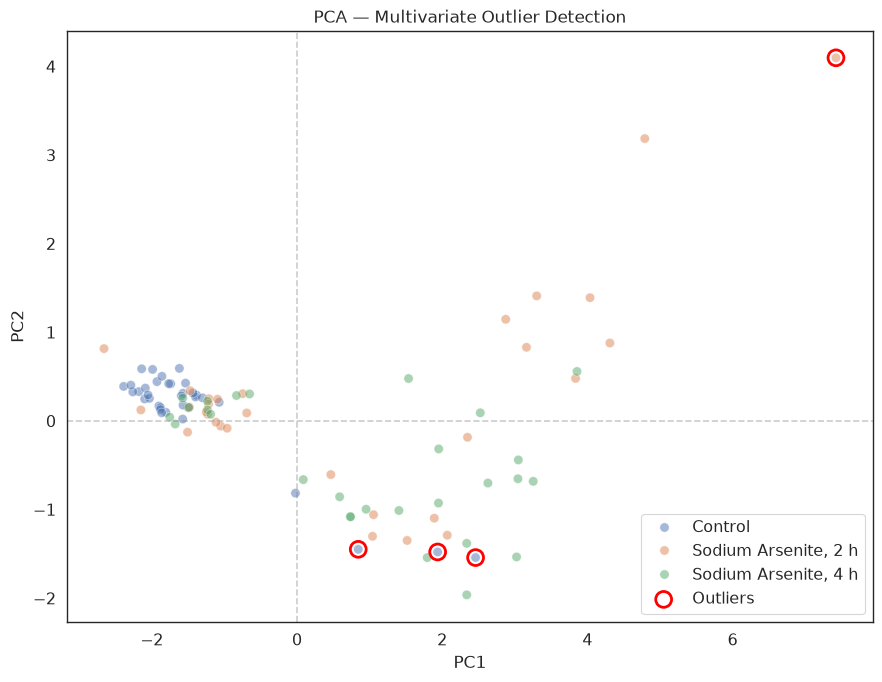

In [43]:
fig, ax = plt.subplots(figsize=(9, 7))

sns.scatterplot(
    data=pca_df_outliers,
    x="PC1",
    y="PC2",
    hue="sample",
    alpha=0.5,
    s=45,
    ax=ax
)

# Highlight outliers
outliers = pca_df_outliers[pca_df_outliers["outlier"]]

ax.scatter(
    outliers["PC1"],
    outliers["PC2"],
    s=130,
    facecolors="none",
    edgecolors="red",
    linewidths=2,
    label="Outliers"
)

ax.axhline(0, color="gray", linestyle="--", alpha=0.4)
ax.axvline(0, color="gray", linestyle="--", alpha=0.4)

ax.set_title("PCA — Multivariate Outlier Detection")
ax.legend()
plt.tight_layout()
plt.show()

In [44]:
df_clean = df.loc[~df.index.isin(outliers.index)].copy()
df_clean.shape

(89, 11)

In [45]:
# Features
features = [
    "n_foci",
    #"area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    #"max_intensity",
]

# Select features and scale them
pca_df = df_clean.copy()

X = df_clean[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

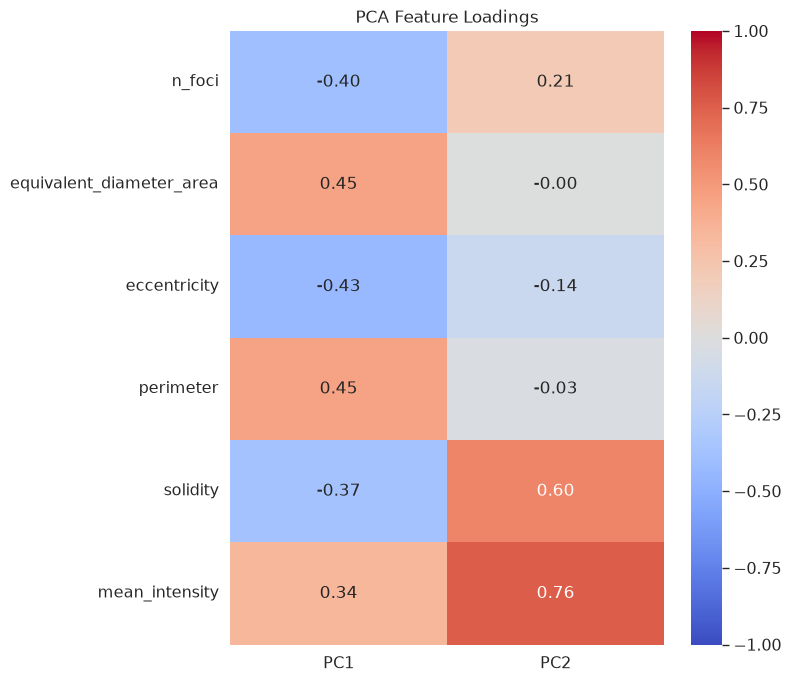

In [46]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

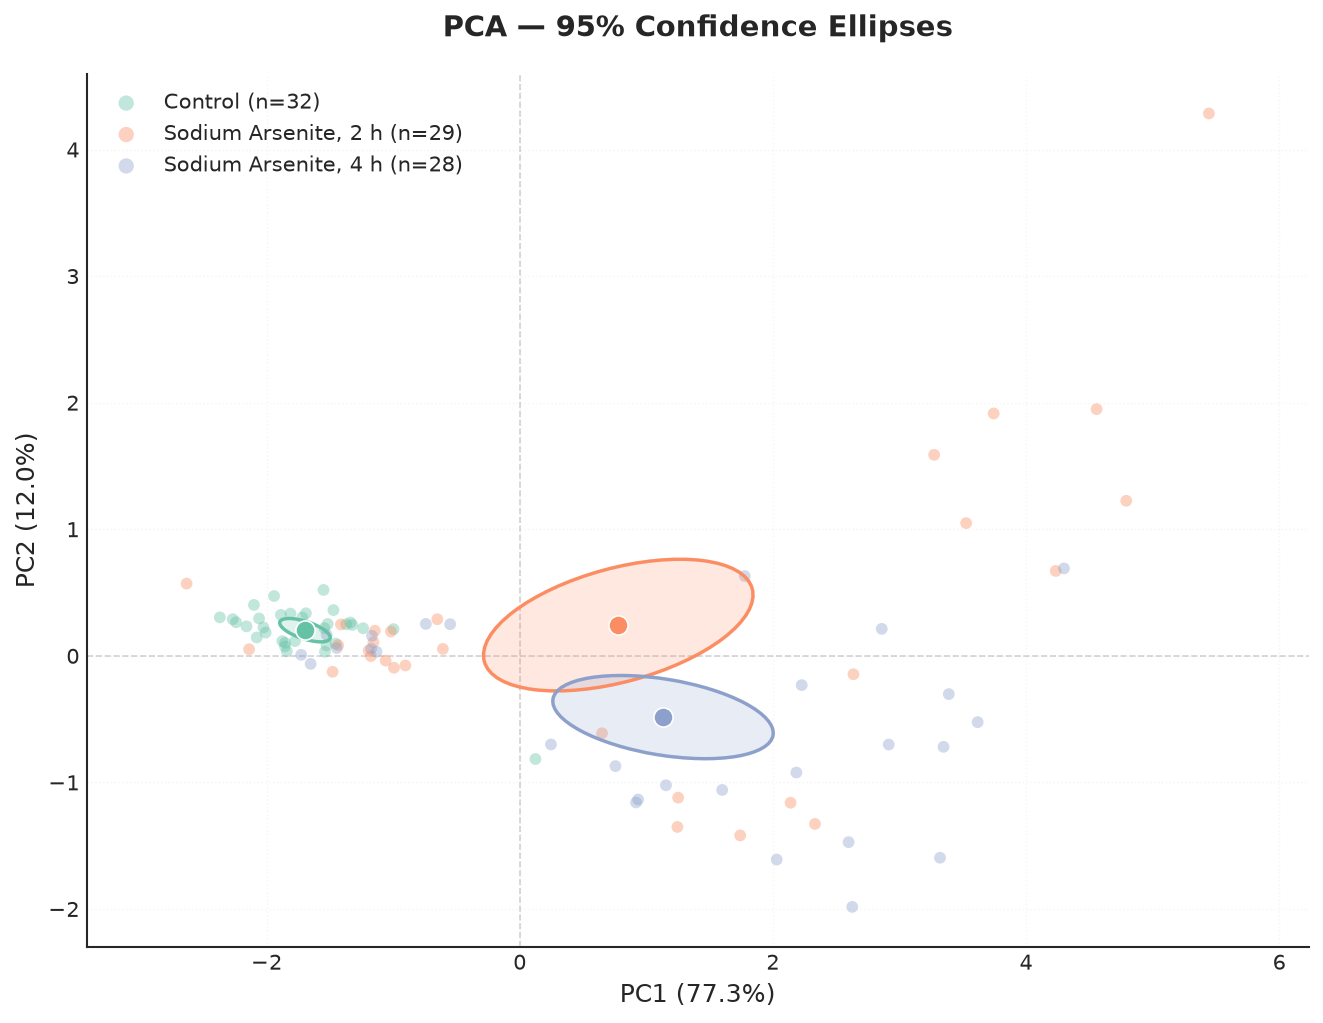

In [47]:
results = bootstrap_pca_centroids(
    pca_df,
    group_col="sample",
    n_boot=5000,
    confidence=0.95,
    pca = pca
)

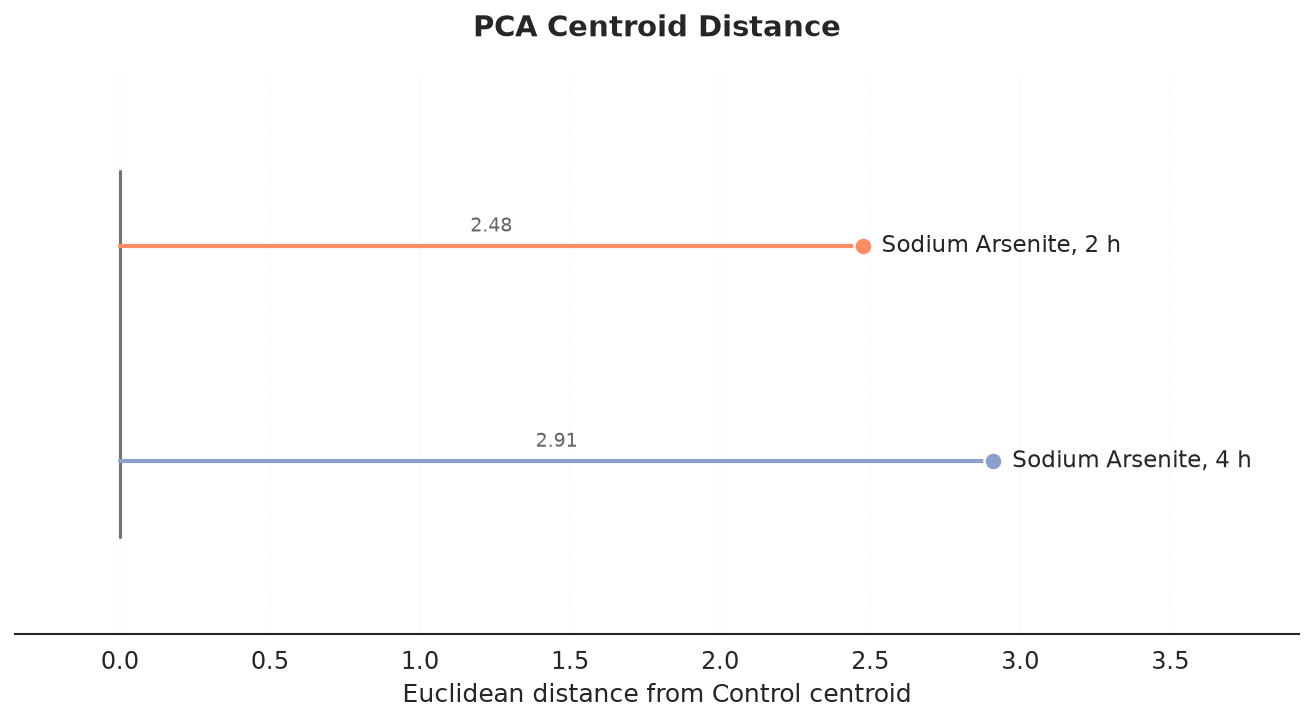

In [48]:
distances = plot_centroid_distance_tree(
    results,
    reference="Control",
    palette="Set2"
)

In [49]:
centroids = pca_df.groupby("sample")[["PC1", "PC2"]].mean()

print(centroids)

                           PC1       PC2
sample                                  
Control              -1.696392  0.202985
Sodium Arsenite, 2 h  0.778674  0.243144
Sodium Arsenite, 4 h  1.132250 -0.483811


In [50]:
results_stats = pca_permanova(
    pca_df,
    group_col="sample"
)

results_stats

,Test,Statistic,p_value,R2,n,groups
0,PERMANOVA,20.739475,0.0001,0.325379,89,3
1,PERMDISP,18.357497,0.0001,NaN,89,3


In [53]:
subset = pca_df[(pca_df['sample'] == "Sodium Arsenite, 2 h") | (pca_df['sample'] == "Sodium Arsenite, 4 h")]

results_stats = pca_permanova(
    subset,
    group_col="sample"
)

results_stats

,Test,Statistic,p_value,R2,n,groups
0,PERMANOVA,1.633692,0.1936,0.028847,57,2
1,PERMDISP,1.040167,0.2639,NaN,57,2
